# Blue/red linear: NF vs YF test
See `PLANblueredLinear.md` (M3). Data: `BRtest/MET0xx.mat`. Per participant: `base_{NF,YF}` (8 trials) and `BR_{NF,YF}_{1,2}` (2 leading baseline samples + 11 steps).
Blue level is linear from 0 to 1700 against a fixed red at 1800.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat

DIR = "/home/sebas/data/blueRedLinear/BRtest/"
PARTICIPANTS = ["MET050", "MET051"]
BLUE = np.linspace(0, 1700, 11)
COLORS = {"NF": "tab:gray", "YF": "goldenrod"}

data = {
    p: {s.name: s for s in loadmat(DIR + p + ".mat", squeeze_me=True, struct_as_record=False)["testData"]}
    for p in PARTICIPANTS
}

# one row per BR step
rows = [
    dict(participant=p, filt=f, rep=r, blue=b, amp=a,
         base_mean=data[p][f"base_{f}"].runData.mean(),
         lead_mean=data[p][f"BR_{f}_{r}"].baselines.mean())
    for p in PARTICIPANTS for f in ["NF", "YF"] for r in [1, 2]
    for b, a in zip(BLUE, data[p][f"BR_{f}_{r}"].runData)
]
df = pd.DataFrame(rows)
df["amp_base"] = df.amp / df.base_mean
df["amp_lead"] = df.amp / df.lead_mean
assert len(df) == 2 * 2 * 2 * 11
df.groupby(["participant", "filt", "rep"])[["base_mean", "lead_mean"]].first()

base_mean  lead_mean
participant filt rep                      
MET050      NF   1     0.728369   0.551094
                 2     0.728369   0.706936
            YF   1     0.709910   0.610647
                 2     0.709910   0.619924
MET051      NF   1     1.483121   0.648603
                 2     1.483121   0.667528
            YF   1     1.384150   0.725371
                 2     1.384150   0.654941

## References: the 8-trial baselines

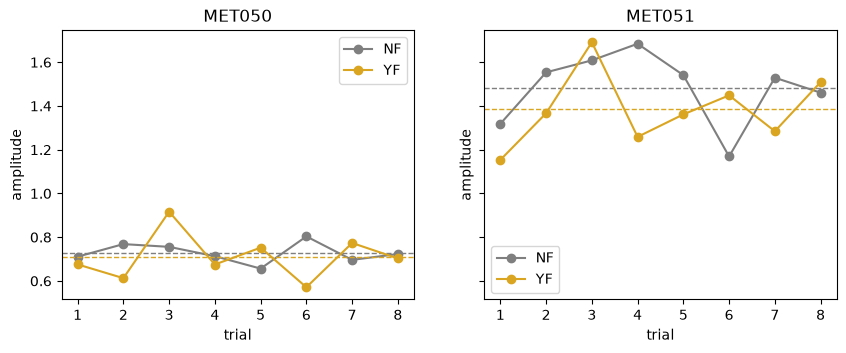

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, p in zip(axes, PARTICIPANTS):
    for f in ["NF", "YF"]:
        y = data[p][f"base_{f}"].runData
        ax.plot(np.arange(1, 9), y, "o-", color=COLORS[f], label=f)
        ax.axhline(y.mean(), color=COLORS[f], ls="--", lw=1)
    ax.set(title=p, xlabel="trial", ylabel="amplitude")
    ax.legend()
plt.show()

## BR runs, raw
Solid = repetition 1, dashed = repetition 2. Horizontal dotted lines: mean of the 8-trial baseline for that filter.

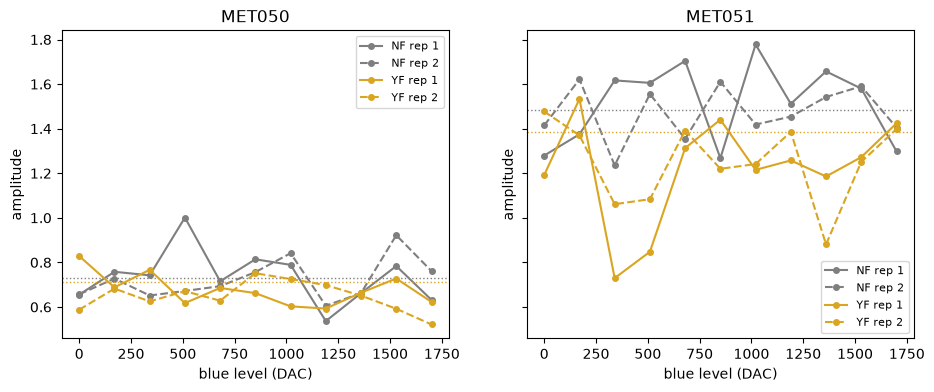

In [3]:
def plot_br(col, ylabel, ref=None):
    fig, axes = plt.subplots(1, len(PARTICIPANTS), figsize=(5.5 * len(PARTICIPANTS), 4), sharey=True)
    for ax, p in zip(axes, PARTICIPANTS):
        for f in ["NF", "YF"]:
            for r, ls in [(1, "-"), (2, "--")]:
                d = df[(df.participant == p) & (df.filt == f) & (df.rep == r)]
                ax.plot(d.blue, d[col], "o" + ls, color=COLORS[f], ms=4, label=f"{f} rep {r}")
            if ref:
                ax.axhline(df[(df.participant == p) & (df.filt == f)][ref].iloc[0], color=COLORS[f], ls=":", lw=1)
        if col != "amp":
            ax.axhline(1, color="k", lw=0.5)
        ax.set(title=p, xlabel="blue level (DAC)", ylabel=ylabel)
        ax.legend(fontsize=8)
    plt.show()

plot_br("amp", "amplitude", ref="base_mean")

## Normalised to the 8-trial baseline mean of the same filter (NF to base_NF, YF to base_YF)

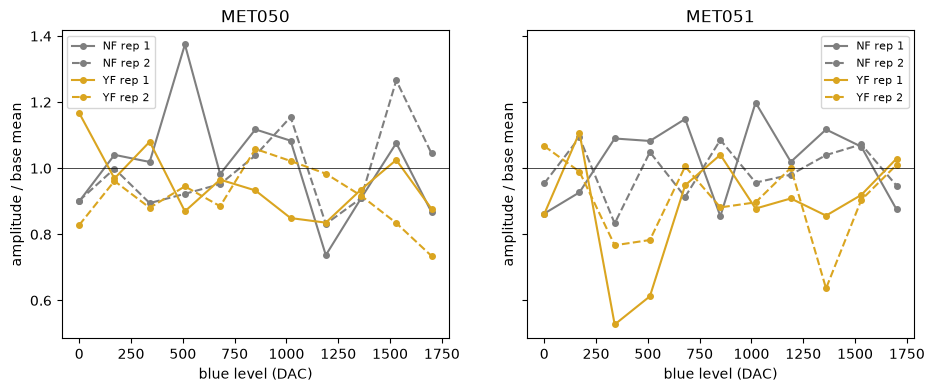

In [4]:
plot_br("amp_base", "amplitude / base mean")

## Normalised to the run's own 2 leading baseline samples

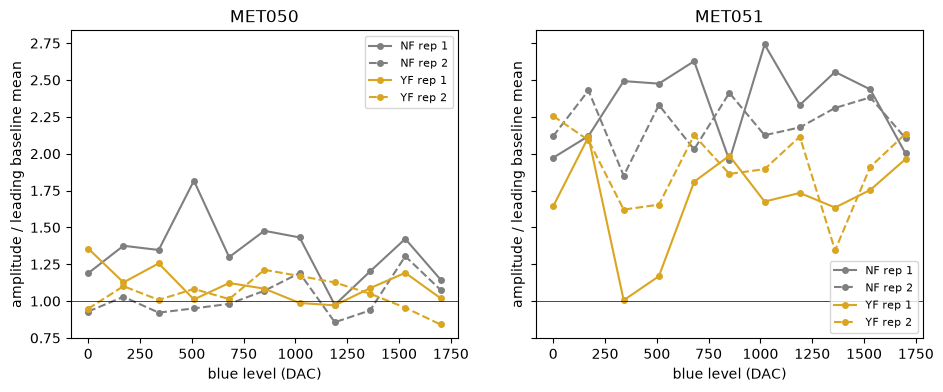

In [5]:
plot_br("amp_lead", "amplitude / leading baseline mean")

## Mean of the 2 repetitions, then baseline
Average the 2 repetitions per filter and blue level first, then divide by the baseline: the 8-trial base mean of that filter, or the mean of the 4 leading baseline samples (2 per repetition).

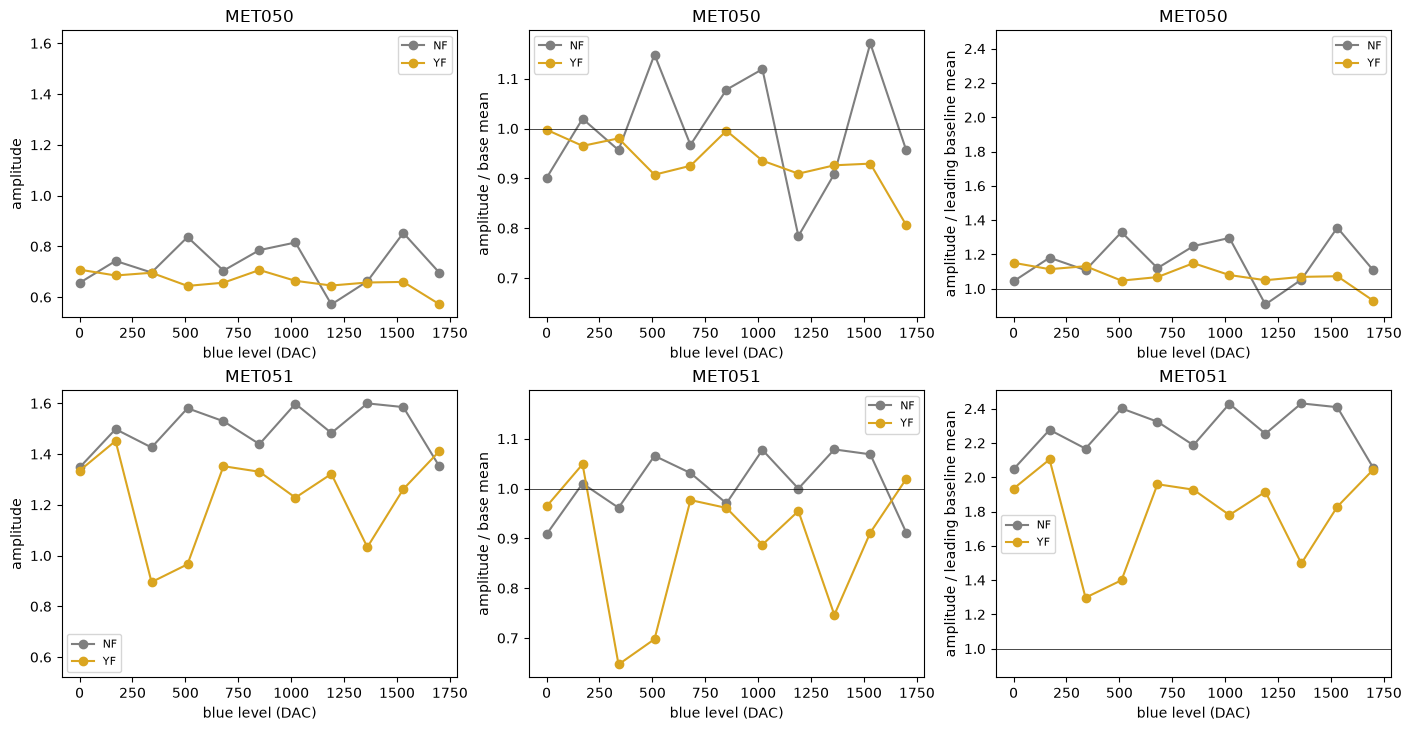

In [6]:
mean_rep = df.groupby(["participant", "filt", "blue"]).agg(
    amp=("amp", "mean"), base_mean=("base_mean", "first"), lead_mean=("lead_mean", "mean")
).reset_index()
mean_rep["amp_base"] = mean_rep.amp / mean_rep.base_mean
mean_rep["amp_lead"] = mean_rep.amp / mean_rep.lead_mean

fig, axes = plt.subplots(len(PARTICIPANTS), 3, figsize=(14, 3.6 * len(PARTICIPANTS)), sharey="col", squeeze=False, layout="constrained")
for row, p in zip(axes, PARTICIPANTS):
    for ax, col, label in zip(row, ["amp", "amp_base", "amp_lead"], ["amplitude", "amplitude / base mean", "amplitude / leading baseline mean"]):
        for f in ["NF", "YF"]:
            d = mean_rep[(mean_rep.participant == p) & (mean_rep.filt == f)]
            ax.plot(d.blue, d[col], "o-", color=COLORS[f], label=f)
        if col != "amp":
            ax.axhline(1, color="k", lw=0.5)
        ax.set(title=p, xlabel="blue level (DAC)", ylabel=label)
        ax.legend(fontsize=8)
plt.show()

## NF - YF difference (mean of the 2 repetitions, then baseline)
Controls should separate; blue-deficient participants should stay near zero.

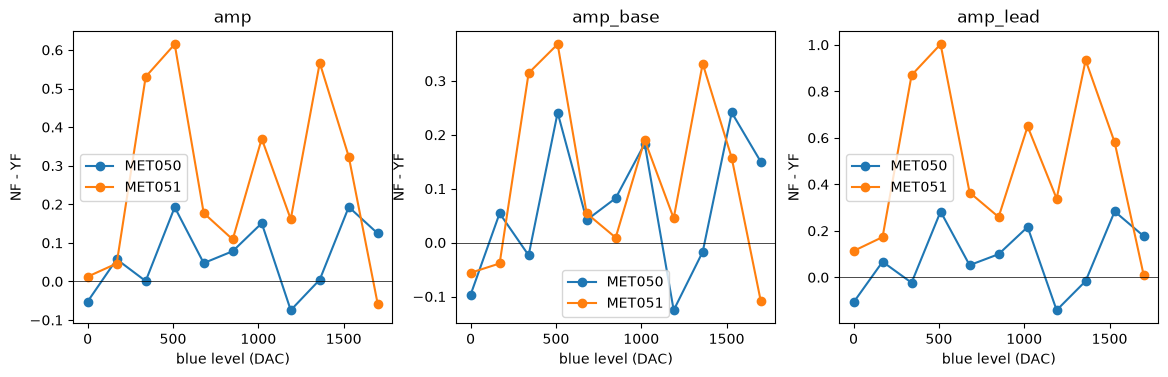

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, ["amp", "amp_base", "amp_lead"]):
    for p in PARTICIPANTS:
        w = mean_rep[mean_rep.participant == p].pivot(index="blue", columns="filt", values=col)
        ax.plot(w.index, w.NF - w.YF, "o-", label=p)
    ax.axhline(0, color="k", lw=0.5)
    ax.set(title=col, xlabel="blue level (DAC)", ylabel="NF - YF")
    ax.legend()
plt.show()